# 04 · Servicio de transporte y actividad

La demanda de [01](01_fuentes_y_demanda.ipynb) indica **cuántas personas necesitan transporte** y la geografía de [02](02_recorridos_y_pendientes.ipynb) describe sus recorridos. Ahora compruebo cómo las atienden los programas de servicio elegidos: qué personas llegan en coche, excursión o lanzadera, cuántos vehículos se programan y cómo se completan las idas y los regresos. Mantengo **2.500.000 visitas-persona durante el año de planificación 2028**, tanto sin intervención como con ella.

**Recibe:** la demanda y geografía aceptadas de la misma ejecución, el Excel registrado y las programaciones fijadas en Silver. **Produce:** la auditoría de los programas, su actividad física y la copia identificada de los insumos que recibirá el balance. **Comprueba:** personas, plazas, recorridos, tiempos, regreso y vehículos disponibles. Las tablas y la figura siguientes presentan esa actividad; aquí no calculo consumo ni ahorro y no busco una programación nueva.

El productor común es [etapas_registradas.py](../src/movilidad_teide/flujos/etapas_registradas.py), que llama a las comprobaciones de [ordenacion_vigente.py](../src/movilidad_teide/flujos/ordenacion_vigente.py). La continuidad entre fechas se contrasta mediante [calendario_vehiculos.py](../src/movilidad_teide/operacion/calendario_vehiculos.py). El código científico permanece en esos módulos; el cuaderno organiza su lectura y muestra agregados.


## 1. Consultar la comprobación o repetirla

Con `consultar` leo la etapa 04 completada de la ejecución distribuida. Con `comprobar` repito las comprobaciones físicas sobre los programas fijados y creo los productos de 04 en la ejecución iniciada en 00. **Antes deben estar completadas 01 y 02 en esa misma ejecución.** No necesito factores de COPERT para comprobar personas, horarios y kilómetros.

La ruta y la acción de la celda siguiente son controles de ejecución, no hipótesis del estudio. Para repetir una etapa ya completada inicio otra ejecución; no sobrescribo sus productos. Cada cuaderno puede abrirse con una sesión de Python nueva. Las salidas guardadas corresponden a una consulta identificada; solo elegir `comprobar` acredita una comprobación nueva.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
from IPython.display import display, Markdown
candidatas = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
RAIZ = next((p for p in candidatas if (p / "pyproject.toml").is_file()
             and (p / "config/parametros_modelo.xlsx").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra este cuaderno desde la raíz del proyecto o desde notebooks/.")
sys.path.insert(0, str(RAIZ / "src"))
from movilidad_teide.configuracion.registro import abrir_ejecucion
from movilidad_teide.flujos.etapas_registradas import ejecutar_etapa
from movilidad_teide.operacion.calendario_vehiculos import materializar_calendario


In [2]:
ACCION_SERVICIO = "consultar"  # Alternativa explícita: "comprobar".
RUTA_EJECUCION = Path("data/silver/ejecuciones/referencia_2028_final_20261116")


In [3]:
if ACCION_SERVICIO not in {"consultar", "comprobar"}:
    raise ValueError('ACCION_SERVICIO debe ser "consultar" o "comprobar".')
EJECUCION = RAIZ / RUTA_EJECUCION
if not (EJECUCION / "registro_ejecucion.json").is_file():
    raise FileNotFoundError("No existe el registro. Inicie 00, complete 01 y 02 e indique la misma ruta.")
DATOS = abrir_ejecucion(RAIZ, EJECUCION)
if ACCION_SERVICIO == "comprobar":
    if any(DATOS["estado_etapas"]["etapas"][s]["estado"] != "completada" for s in ["01", "02"]):
        raise ValueError("Complete 01 y 02 en esta misma ejecución antes de comprobar el servicio.")
    ejecutar_etapa(RAIZ, EJECUCION, "04", accion="comprobar")
    DATOS = abrir_ejecucion(RAIZ, EJECUCION)
ETAPA = DATOS["estado_etapas"]["etapas"]["04"]
if ETAPA["estado"] != "completada":
    raise ValueError("No hay servicio comprobado. Complete 01 y 02 y elija comprobar en esta ejecución.")
SERVICIO = EJECUCION / ETAPA["carpeta"]
INSUMOS = SERVICIO / "insumos"
CFG = DATOS["configuracion"]["valores"]
V = DATOS["configuracion"]["valores_modelo"]
CAPTURA = INSUMOS / DATOS["configuracion"]["indice"]["captura"]
def leer(p):
    return pd.read_csv(p, sep=";", float_precision="round_trip")
ACTIVIDAD = leer(SERVICIO / "actividad_programas.csv")
AUDITORIA = leer(SERVICIO / "auditoria_programas.csv")
DISTANCIAS = leer(SERVICIO / "distancias_comprobadas.csv")
INDICE_INSUMOS = json.loads((SERVICIO / "indice_insumos_fijados.json").read_text())
print("Acción realizada:", ACCION_SERVICIO)
print("Ejecución:", DATOS["registro"]["identificador"])
print("Carpeta de productos:", ETAPA["carpeta"])
print("Resultado de la etapa:", ETAPA["resultado"])
print("COPERT y energía no se ejecutan en este cuaderno.")

def mostrar(tabla, titulo, formatos=None):
    display(tabla.style.set_uuid("servicio04").hide(axis="index").set_caption(titulo)
            .format(formatos or {}, decimal=",", thousands=" ", na_rep="No procede"))


Acción realizada: consultar
Ejecución: referencia_2028_paquetes_20261116
Carpeta de productos: resultados/04/edb4658dccce43a19a8bb2b4496d72a6
Resultado de la etapa: {'distancias_dirigidas_comprobadas': 8, 'energia_calculada': False, 'programacion_fijada': True, 'programas_comprobados': 261}
COPERT y energía no se ejecutan en este cuaderno.


## 2. Qué estoy contando

Una **visita-persona** es una persona que visita el Parque ese día; la vuelta no crea otra visita. Una misma persona puede venir otro día y contar entonces como otra visita. Un **embarque** es subir a un vehículo: una visita en lanzadera tiene, en los programas adoptados, un embarque de ida y otro de regreso. Una **expedición comercial** es una salida en un sentido que ofrece plazas; un autobús realiza varias a lo largo del día. Un **movimiento en vacío** traslada el autobús sin visitantes y también recorre kilómetros.

La **unidad física** es el autobús identificable. Programarlo no significa que circule continuamente ni que haga una sola expedición. Las **sustitutas** se mantienen disponibles y no se suman como expediciones comerciales. Las sumas de unidades por fecha son **unidades-día**, no autobuses distintos que haya que comprar.

**Tabla 1. Condiciones de capacidad y operación del servicio del Teide, 2028.** Procedencia: 31 condiciones efectivas del Excel de esta ejecución; la capacidad nominal se lee de su configuración técnica. Las cifras se mantienen sin editar hipótesis.


In [4]:
condiciones = pd.DataFrame([
    ("Cupo ordinario global", CFG["cupo_ordinario"], "coches que entran al Parque/día"),
    ("Propias disponibles", CFG["propias"], "autobuses físicos"),
    ("Máximo propias ordinaria", CFG["max_programadas_ordinaria"], "autobuses programados/día"),
    ("Sustitutas propias ordinaria, mínimo", CFG["sustitutas_ordinaria"], "autobuses disponibles/día"),
    ("Punta sin externas: máximo propias", CFG["max_programadas_punta_propia"], "autobuses programados/día"),
    ("Punta con externas: máximo propias", CFG["max_programadas_punta"], "autobuses programados/día"),
    ("Sustitutas al programar treinta propias", CFG["externas_con_30"], "autobuses externos disponibles/día"),
    ("Plazas comerciales por expedición de lanzadera", CFG["plazas_diseno"], "personas"),
    ("Capacidad nominal del autobús representativo", V["plazas_guagua"], "plazas"),
    ("Carga media del coche", CFG["ocupacion_coche"], "personas/vehículo"),
    ("Carga media de excursión", CFG["ocupacion_guagua_aforo"], "personas/autocar"),
    ("Estancia mínima entre entrada y regreso al Parque", CFG["estancia_min"], "minutos"),
    ("Intervalo mínimo por cabecera y sentido", CFG["intervalo_min"], "minutos"),
    ("Regulación entre movimientos de una unidad", CFG["regulacion_min"], "minutos"),
    ("Margen de regreso antes del ocaso", CFG["margen_ocaso_min"], "minutos"),
], columns=["Condición", "Valor", "Unidad"])
mostrar(condiciones, "Tabla 1 · Capacidad y condiciones del servicio del Teide · 2028", {"Valor":"{:,.2f}"})


Condición,Valor,Unidad
Cupo ordinario global,"650,00",coches que entran al Parque/día
Propias disponibles,"30,00",autobuses físicos
Máximo propias ordinaria,"27,00",autobuses programados/día
"Sustitutas propias ordinaria, mínimo","3,00",autobuses disponibles/día
Punta sin externas: máximo propias,"28,00",autobuses programados/día
Punta con externas: máximo propias,"30,00",autobuses programados/día
Sustitutas al programar treinta propias,"2,00",autobuses externos disponibles/día
Plazas comerciales por expedición de lanzadera,"46,00",personas
Capacidad nominal del autobús representativo,"55,00",plazas
Carga media del coche,"3,20",personas/vehículo


El cupo de coches cuenta **entradas al Parque**, no los coches que llegan a las cabeceras para enlazar con una lanzadera. Los coches autorizados realizan también la visita interior en coche en los dos escenarios modelizados. Trasladar después a sus ocupantes a lanzaderas interiores es una mejora futura que exige dimensionar otro servicio; aquí no se le atribuye capacidad ni ahorro.

Las personas que pasan del coche a la lanzadera llegan en coche particular a su cabecera asignada. Se trata igual a los viajeros que antes utilizaban las líneas de acceso 342 y 348 de Transportes Interurbanos de Tenerife (TITSA). Su viaje a la cabecera forma parte de la actividad del balance, aunque no consume cupo de entrada al Parque. **No sumo esas personas una segunda vez como visitantes en coche.** La carga media de 3,2 personas por coche se aplica a esos accesos; las reasignaciones de cabecera conservan el origen y el regreso de cada grupo.

Las excursiones representan el transporte colectivo restante tras separar TITSA. En la comparación principal se mantiene su demanda. Dividir sus visitas entre 35,99 personas por autocar permite expresar **servicios equivalentes de ida y regreso**, no una flota identificada ni un horario comprobado. Su carga es una media de los datos de aforo, no una reserva real de cada salida. Sobre las 55 plazas del autocar representativo equivale al 65,4 %. La ocupación de lanzaderas se comprueba de otra forma: embarques divididos entre las **46 plazas comerciales por expedición**; también muestro su proporción respecto a las 55 nominales. No confundo ninguna de estas magnitudes con la carga técnica usada por COPERT.


## 3. Programas comprobados y calendario adoptado

Un **perfil diario** reúne una combinación de mes y tipo de día; el calendario distribuye esos perfiles entre las 366 fechas de 2028. El registro comprueba varios programas para un mismo perfil: distintos cupos, límites de flota y sensibilidades de excursiones. **Los 261 programas no son 261 días ni 261 autobuses.** Solo una selección forma la programación anual recomendada.

La tabla 2 separa los programas de la comparación principal de los de sensibilidad. La comprobación común verifica las personas de cada cabecera, la reasignación admisible por origen, la reserva completa de ida y regreso, los tiempos y el cierre de existencias de vehículos por base. Además contrasta ocho distancias de acceso con los recorridos de 02. Una coincidencia numérica no acredita la disponibilidad real de vehículos, paradas o permisos.

**Tabla 2. Programas físicos comprobados en la ejecución seleccionada.** Fuente: `actividad_programas.csv`, `auditoria_programas.csv` y `distancias_comprobadas.csv` de 04. Los programas alternativos no se acumulan en la actividad anual.


In [5]:
assert len(ACTIVIDAD) == len(AUDITORIA) and AUDITORIA.cierre.all()
np.testing.assert_allclose(DISTANCIAS.km_geografia, DISTANCIAS.km_servicio, rtol=0, atol=1e-8)
resumen_programas = (ACTIVIDAD.groupby(["familia", "incremento_excursiones"], sort=False)
                     .size().rename("Programas comprobados").reset_index())
resumen_programas["Familia"] = resumen_programas.familia.map({"principal":"Comparación principal", "sensibilidad_excursiones":"Sensibilidad de excursiones"})
resumen_programas["Aumento de visitas de excursión frente a sin intervención (%)"] = 100 * resumen_programas.incremento_excursiones
mostrar(resumen_programas[["Familia", "Aumento de visitas de excursión frente a sin intervención (%)", "Programas comprobados"]],
        "Tabla 2 · Programas alternativos comprobados · Teide, referencia 2028", {"Aumento de visitas de excursión frente a sin intervención (%)":"{:,.0f}"})
print("Distancias dirigidas de acceso equivalentes:", len(DISTANCIAS))


Familia,Aumento de visitas de excursión frente a sin intervención (%),Programas comprobados
Comparación principal,0,117
Sensibilidad de excursiones,10,72
Sensibilidad de excursiones,25,72


Distancias dirigidas de acceso equivalentes: 8


Para presentar el año adopté el criterio vigente: **priorizar los programas sin apoyos externos y, entre ellos, el menor cupo ensayado**; después se ordena por unidades programadas y límite del programa. Es el mismo orden explícito de `_anualizar_politicas` en el módulo común. La celda siguiente es una vista de esos programas ya fijados y comprobados: no modifica horarios, reserva plazas nuevas ni ejecuta una búsqueda. La equivalencia de esta vista con el calendario vigente se contrasta en la aceptación del cuaderno.

La jornada es **ordinaria** cuando utiliza el cupo de 650 y como máximo 27 propias, sin externas. El resto de fechas seleccionadas son **puntas**: pueden necesitar 28 propias con dos propias libres o treinta propias con dos externas disponibles para sustitución; el cupo pasa a 700 o 750 solo en las fechas seleccionadas. Las externas no se programan como servicio comercial adicional.

El año mostrado es un **calendario de planificación**, obtenido del reparto anual de la demanda de 01. No es una predicción de reservas de cada fecha ni promete cubrir todos los extremos observados. Las decisiones reales se revisarán por cabecera, hora y regreso antes de confirmar reservas.


In [6]:
programas = leer(CAPTURA / "resultados_operacion.csv")
programas = programas.loc[programas.cierre].copy()
seleccion = (programas.sort_values(["externas_disponibles", "cupo", "programadas", "max_programadas"], kind="stable")
             .drop_duplicates("perfil"))
calendario_base = leer(CAPTURA / "calendario.csv")
CALENDARIO = calendario_base.merge(seleccion, left_on="target", right_on="perfil", validate="many_to_one", suffixes=("", "_programa"))
assert len(CALENDARIO) == len(calendario_base) == 366 and CALENDARIO.fecha.nunique() == 366
CALENDARIO["regimen"] = np.where((CALENDARIO.programadas <= CFG["max_programadas_ordinaria"])
    & CALENDARIO.externas_disponibles.eq(0) & CALENDARIO.cupo.eq(CFG["cupo_ordinario"]), "Ordinaria", "Punta")
for col in ["cupo", "max_programadas", "programadas", "externas_disponibles", "externas_programadas"]:
    CALENDARIO[col] = CALENDARIO[col].astype(int)
assert CALENDARIO.externas_programadas.eq(0).all()


## 4. Personas y actividad del programa elegido

Leo los objetivos, reservas, salidas y movimientos de cada programa seleccionado dentro de los insumos identificados de 04. La tabla 3a compara el reparto anual sin y con intervención; la tabla 3b asigna a cada fecha **una sola vez** sus visitas en coche directo, excursión y lanzadera; el total con intervención debe coincidir con las visitas sin intervención y con 2.500.000 al año. Los servicios de lanzadera y sus kilómetros proceden de los movimientos comprobados, no de multiplicar una flota máxima por todos los días.

Los valores fraccionarios representan flujos medios modelizados. Solo redondeo para presentar tablas; las comprobaciones se hacen antes de redondear. El cociente de visitas de excursión entre su carga media da autocares equivalentes de ida y regreso; multiplicarlo por dos da expediciones equivalentes en un sentido. Para el coche uso entradas y viajes de acceso equivalentes, no una lista de matrículas.


In [7]:
filas = []; PLANTILLAS = {}
for r in seleccion.itertuples():
    cupo, maximas = int(r.cupo), int(r.max_programadas)
    carpeta = CAPTURA / "ofertas" / str(cupo) / str(maximas) / r.perfil
    objetivos, reservas, viajes, movimientos = [leer(carpeta / (n + ".csv")) for n in ["objetivos", "reservas", "viajes", "movimientos"]]
    n_lanzadera = float(objetivos.demanda_lanzadera_dia.sum())
    comercial = movimientos.componente.eq("comercial")
    np.testing.assert_allclose([reservas.personas.sum(), viajes.personas.sum()], [n_lanzadera, 2*n_lanzadera], rtol=0, atol=1e-8)
    PLANTILLAS[r.perfil] = dict(objetivos=objetivos, reservas=reservas, viajes=viajes, movimientos=movimientos)
    filas.append(dict(perfil=r.perfil, visitas_sin=float(objetivos.visitas_sin_dia.sum()),
        visitas_coche=float(objetivos.visitas_coche_autorizadas_dia.sum()),
        visitas_excursion=float(objetivos.visitas_excursiones_con_intervencion_dia.sum()),
        visitas_lanzadera=n_lanzadera, visitas_titsa_sin=float(objetivos.visitas_titsa.sum()),
        visitas_coche_sin=float(objetivos.visitas_coche.sum()),
        coches_parque=float(objetivos.coches_autorizados_dia.sum()),
        coches_cabecera_equivalentes=n_lanzadera/CFG["ocupacion_coche"],
        autocares_excursion_equivalentes=float(objetivos.visitas_excursiones_con_intervencion_dia.sum())/CFG["ocupacion_guagua_aforo"],
        expediciones=int(comercial.sum()), vacios=int((~comercial).sum()),
        km_comerciales=float(movimientos.loc[comercial,"km"].sum()), km_vacios=float(movimientos.loc[~comercial,"km"].sum())))
FISICA = pd.DataFrame(filas)
CALENDARIO = CALENDARIO.merge(FISICA, on="perfil", validate="many_to_one").sort_values("fecha").reset_index(drop=True)
np.testing.assert_allclose(CALENDARIO[["visitas_coche","visitas_excursion","visitas_lanzadera"]].sum(axis=1), CALENDARIO.visitas_sin, rtol=0, atol=1e-8)
np.testing.assert_allclose(CALENDARIO.visitas_sin.sum(), CFG["visitas_anio"], rtol=0, atol=1e-8)
assert (CALENDARIO.coches_parque <= CALENDARIO.cupo + 1e-8).all()
ANUAL = CALENDARIO.groupby("regimen", sort=False)[["visitas_sin","visitas_coche","visitas_excursion","visitas_lanzadera","coches_parque","coches_cabecera_equivalentes","autocares_excursion_equivalentes","expediciones","vacios","km_comerciales","km_vacios"]].sum()
ANUAL.insert(0,"dias",CALENDARIO.groupby("regimen",sort=False).size())
ANUAL.loc["Total anual"] = ANUAL.sum()
visitas = ANUAL[["dias","visitas_sin","visitas_coche","visitas_excursion","visitas_lanzadera"]].reset_index().rename(columns={"regimen":"Régimen","dias":"Fechas (días)","visitas_sin":"Visitas totales", "visitas_coche":"Visitas en coche al Parque", "visitas_excursion":"Visitas en excursión", "visitas_lanzadera":"Visitas en lanzadera"})
comparacion_modos = pd.DataFrame({"Modo de acceso al Parque":["Coche directo", "Excursión", "TITSA de acceso", "Lanzadera", "Total"],
    "Sin intervención (visitas-persona/año)":[CALENDARIO.visitas_coche_sin.sum(), CALENDARIO.visitas_excursion.sum(), CALENDARIO.visitas_titsa_sin.sum(), 0, CALENDARIO.visitas_sin.sum()],
    "Con intervención (visitas-persona/año)":[CALENDARIO.visitas_coche.sum(), CALENDARIO.visitas_excursion.sum(), 0, CALENDARIO.visitas_lanzadera.sum(), CALENDARIO.visitas_sin.sum()]})
for col in comparacion_modos.columns[1:]:
    np.testing.assert_allclose(comparacion_modos[col].iloc[:-1].sum(), CFG["visitas_anio"], rtol=0, atol=1e-8)
mostrar(comparacion_modos,"Tabla 3a · Visitas-persona por modo de acceso sin y con intervención · Teide, 2028 · Fuente: objetivos de 04",{x:"{:,.0f}" for x in comparacion_modos.columns if x!="Modo de acceso al Parque"})
mostrar(visitas,"Tabla 3b · Visitas-persona por régimen con intervención · Teide, 366 fechas de 2028 · Fuente: objetivos comprobados de 04", {x:"{:,.0f}" for x in visitas.columns if x!="Régimen"})


Modo de acceso al Parque,Sin intervención (visitas-persona/año),Con intervención (visitas-persona/año)
Coche directo,1 907 863,771 840
Excursión,578 351,578 351
TITSA de acceso,13 786,0
Lanzadera,0,1 149 809
Total,2 500 000,2 500 000


Régimen,Fechas (días),Visitas totales,Visitas en coche al Parque,Visitas en excursión,Visitas en lanzadera
Ordinaria,266,1 738 981,553 280,401 676,784 025
Punta,100,761 019,218 560,176 675,365 784
Total anual,366,2 500 000,771 840,578 351,1 149 809


**Tabla 4. Actividad de transporte con intervención durante las 366 fechas de 2028.** Fuente: programas físicos de 04, ponderados por el calendario adoptado. La carga del coche es 3,2 personas; la de excursión, 35,99. Las entradas de coches al Parque y los accesos en coche a las cabeceras son actividades distintas. Los autocares equivalentes incluyen una ida y un regreso por servicio; no identifican vehículos físicos ni validan su disponibilidad comercial. Los kilómetros en vacío pertenecen a las lanzaderas propias; el desplazamiento potencial de las externas para estar disponibles se valora separadamente en el balance de 06.


In [8]:
servicios = ANUAL[["coches_parque","coches_cabecera_equivalentes","autocares_excursion_equivalentes","expediciones","vacios","km_comerciales","km_vacios"]].reset_index().rename(columns={"regimen":"Régimen","coches_parque":"Entradas de coches al Parque", "coches_cabecera_equivalentes":"Accesos equivalentes en coche a cabeceras (ida y regreso)","autocares_excursion_equivalentes":"Servicios equivalentes de excursión (ida y regreso)","expediciones":"Expediciones comerciales de lanzadera (un sentido)","vacios":"Movimientos de lanzadera en vacío", "km_comerciales":"Lanzadera: vehículo·km comerciales", "km_vacios":"Lanzadera: vehículo·km en vacío"})
mostrar(servicios,"Tabla 4 · Actividad con intervención · Teide, año 2028 · Flujos equivalentes y movimientos comprobados",{x:"{:,.1f}" for x in servicios.columns if x!="Régimen"})


Régimen,Entradas de coches al Parque,Accesos equivalentes en coche a cabeceras (ida y regreso),Servicios equivalentes de excursión (ida y regreso),Expediciones comerciales de lanzadera (un sentido),Movimientos de lanzadera en vacío,Lanzadera: vehículo·km comerciales,Lanzadera: vehículo·km en vacío
Ordinaria,"172 900,0","245 007,8","11 160,8","35 042,0","12 815,0","1 108 632,9","458 893,3"
Punta,"68 300,0","114 307,6","4 909,0","16 386,0","5 832,0","518 114,3","219 673,1"
Total anual,"241 200,0","359 315,4","16 069,8","51 428,0","18 647,0","1 626 747,2","678 566,4"


**Tabla 5. Ocupación de los transportes colectivos y carga del coche con intervención, 2028.** Fuente: visitas y expediciones de las tablas 3–4 y capacidades registradas. La ocupación de lanzadera pondera todas las expediciones comerciales; no es la media simple de porcentajes diarios. Cada visita cuenta dos embarques. Los vacíos no ofrecen plazas y no entran en ese denominador; sus kilómetros sí se incluyen en la actividad. El porcentaje nominal del autocar representativo usa 55 plazas, tanto para excursiones como para lanzaderas; las 46 comerciales se aplican solo a lanzaderas. La carga del coche se mantiene como personas por coche, sin inventar una capacidad nominal del parque de turismos.


In [9]:
ocupacion = pd.DataFrame({"Régimen":ANUAL.index,
    "Personas/coche (hipótesis)":CFG["ocupacion_coche"],
    "Personas/autocar de excursión (media de aforo)":CFG["ocupacion_guagua_aforo"],
    "Excursión: ocupación de 55 plazas nominales (%)":100*CFG["ocupacion_guagua_aforo"]/V["plazas_guagua"],
    "Lanzadera: embarques comerciales":2*ANUAL.visitas_lanzadera.to_numpy(),
    "Lanzadera: personas por expedición":(2*ANUAL.visitas_lanzadera/ANUAL.expediciones).to_numpy(),
    "Lanzadera: ocupación de 46 plazas comerciales (%)":(200*ANUAL.visitas_lanzadera/ANUAL.expediciones/CFG["plazas_diseno"]).to_numpy(),
    "Lanzadera: ocupación de 55 plazas nominales (%)":(200*ANUAL.visitas_lanzadera/ANUAL.expediciones/V["plazas_guagua"]).to_numpy()})
assert (ocupacion["Lanzadera: ocupación de 46 plazas comerciales (%)"] <= 100+1e-8).all()
mostrar(ocupacion,"Tabla 5 · Carga media y ocupación con intervención · Teide, 2028 · Dos embarques por visita en lanzadera",{x:"{:,.2f}" for x in ocupacion.columns if x!="Régimen"})


Régimen,Personas/coche (hipótesis),Personas/autocar de excursión (media de aforo),Excursión: ocupación de 55 plazas nominales (%),Lanzadera: embarques comerciales,Lanzadera: personas por expedición,Lanzadera: ocupación de 46 plazas comerciales (%),Lanzadera: ocupación de 55 plazas nominales (%)
Ordinaria,"3,20","35,99","65,44","1 568 050,18","44,75","97,28","81,36"
Punta,"3,20","35,99","65,44","731 568,36","44,65","97,06","81,17"
Total anual,"3,20","35,99","65,44","2 299 618,55","44,72","97,21","81,30"


## 5. Cuándo cambia la flota programada

La tabla 6 distingue los seis tamaños que aparecen realmente en el calendario adoptado. **27 es el máximo ordinario**: los días de menor demanda se programan 20, 23 o 24 unidades. La figura 1 sitúa estas fechas en el año y permite ver en qué meses aparece la punta. El calendario completo permanece en la variable `CALENDARIO` y sus programas se localizan mediante el índice de insumos; no hay que interpretar un promedio anual como flota fija diaria.

**Tabla 6. Días por régimen, cupo y número de lanzaderas propias programadas, Teide 2028.** Fuente: calendario adoptado y programas comprobados de 04. Las unidades propias libres y las externas disponibles se reservan para sustituciones y no se añaden a las salidas comerciales. Las fechas se cuentan una sola vez; no se acumulan los programas alternativos.


In [10]:
CALENDARIO["propias_libres"] = CFG["propias"] - CALENDARIO.programadas
CALENDARIO["sustitutas_disponibles"] = CALENDARIO.propias_libres + CALENDARIO.externas_disponibles
ordinarias = CALENDARIO.regimen.eq("Ordinaria")
assert CALENDARIO.loc[ordinarias,"propias_libres"].ge(CFG["sustitutas_ordinaria"]).all()
assert CALENDARIO.loc[~ordinarias,"sustitutas_disponibles"].ge(CFG["sustitutas_punta"]).all()
assert CALENDARIO.programadas.le(CFG["max_programadas_punta"]).all()
assert CALENDARIO.loc[CALENDARIO.programadas.eq(CFG["propias"]),"externas_disponibles"].eq(CFG["externas_con_30"]).all()
flotas = CALENDARIO.groupby(["regimen","cupo","programadas","propias_libres","externas_disponibles"],sort=True).size().rename("Días").reset_index().rename(columns={"regimen":"Régimen","cupo":"Cupo de coches/día","programadas":"Propias programadas/día","propias_libres":"Propias libres/día","externas_disponibles":"Externas para sustitución/día"})
mostrar(flotas,"Tabla 6 · Distribución anual de flotas propias y sustitución · Teide, 2028 · Fuente: programas adoptados de 04")


Régimen,Cupo de coches/día,Propias programadas/día,Propias libres/día,Externas para sustitución/día,Días
Ordinaria,650,20,10,0,85
Ordinaria,650,23,7,0,18
Ordinaria,650,24,6,0,110
Ordinaria,650,27,3,0,53
Punta,650,28,2,0,52
Punta,650,30,0,2,4
Punta,700,28,2,0,13
Punta,700,30,0,2,9
Punta,750,28,2,0,22


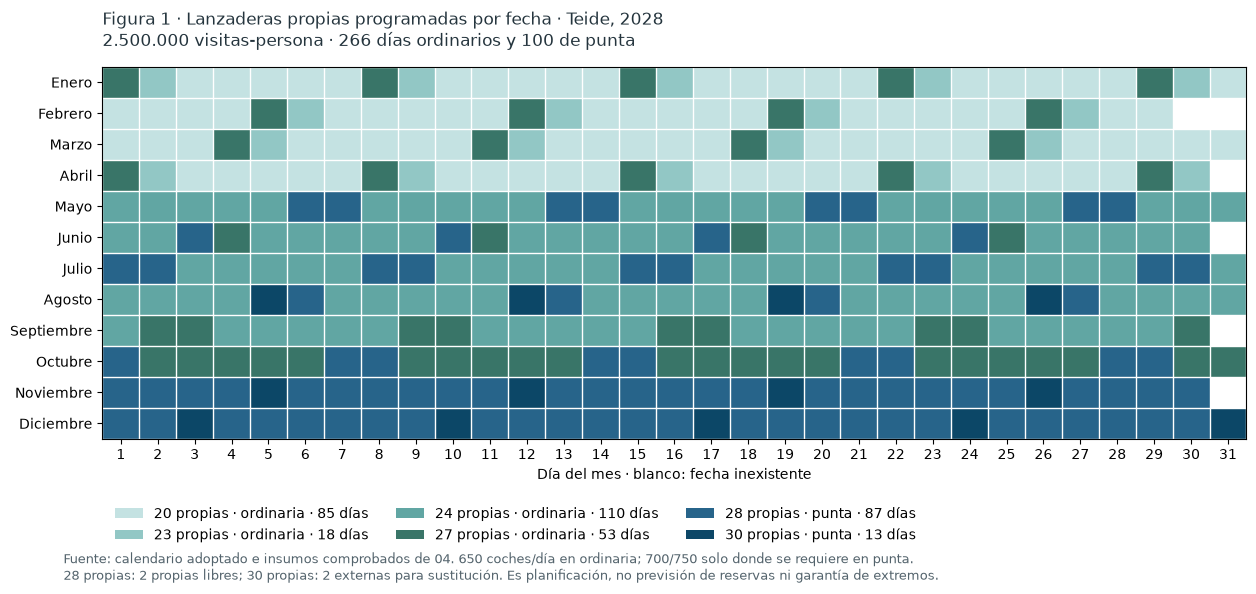

In [11]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
fechas = pd.to_datetime(CALENDARIO.fecha)
matriz = np.full((12,31),np.nan)
for fecha, n in zip(fechas,CALENDARIO.programadas):
    matriz[fecha.month-1,fecha.day-1] = n
niveles = sorted(CALENDARIO.programadas.unique())
colores = ["#C4E2E2","#92C7C5","#61A6A3","#397568","#27648A","#0C4767"]
fig, ax = plt.subplots(figsize=(13,6))
ax.imshow(np.ma.masked_invalid(matriz),aspect="auto",cmap=ListedColormap(colores),
          norm=BoundaryNorm([19,21.5,23.5,25.5,27.5,29,31],6))
ax.set(xticks=np.arange(31),xticklabels=np.arange(1,32),yticks=np.arange(12),
       yticklabels=["Enero","Febrero","Marzo","Abril","Mayo","Junio","Julio","Agosto","Septiembre","Octubre","Noviembre","Diciembre"],
       xlabel="Día del mes · blanco: fecha inexistente")
ax.set_title(f"Figura 1 · Lanzaderas propias programadas por fecha · Teide, 2028\n2.500.000 visitas-persona · {int(ordinarias.sum())} días ordinarios y {int((~ordinarias).sum())} de punta",loc="left",color="#24343D",pad=15)
ax.set_xticks(np.arange(-.5,31,1),minor=True);ax.set_yticks(np.arange(-.5,12,1),minor=True)
ax.grid(which="minor",color="white",linewidth=1);ax.tick_params(which="minor",bottom=False,left=False)
ax.legend(handles=[Patch(facecolor=colores[i],label=f"{n} propias · {'ordinaria' if n<=CFG['max_programadas_ordinaria'] else 'punta'} · {int(CALENDARIO.programadas.eq(n).sum())} días") for i,n in enumerate(niveles)],loc="upper left",bbox_to_anchor=(0,-.15),ncol=3,frameon=False)
fig.text(.07,.015,"Fuente: calendario adoptado e insumos comprobados de 04. 650 coches/día en ordinaria; 700/750 solo donde se requiere en punta.\n28 propias: 2 propias libres; 30 propias: 2 externas para sustitución. Es planificación, no previsión de reservas ni garantía de extremos.",fontsize=9,color="#53636C")
fig.subplots_adjust(bottom=.25,left=.1,right=.98,top=.87)
plt.show()


## 6. Regresos y continuidad de las treinta unidades

Las plazas anuales por sí solas no demuestran que un servicio sea viable. La auditoría de 04 comprueba la reserva pareada de cada grupo, al menos dos horas entre entrada al Parque y comienzo de regreso, intervalos mínimos de quince minutos por cabecera y sentido, diez minutos de regulación entre movimientos y el margen de treinta minutos antes del ocaso en el regreso a la cabecera. La salida de base no precede a las 07:00; el cierre de bases es a las 21:30 de mayo a agosto y a las 20:00 el resto del año.

La comprobación adicional siguiente llama al materializador común para enlazar las fechas con las **mismas treinta identidades físicas**. Puede reasignar qué unidad ejecuta una cadena al día siguiente, conservando recorridos y horas; no inventa traslados entre bases ni usa las externas como salidas nuevas. Se obtienen 30 estados de disponibilidad por fecha: **10.980 estados unidad-día**, no 10.980 autobuses. Estas vistas se mantienen en memoria: los productos sellados de 04 no se modifican.


In [12]:
inventario = leer(INSUMOS / "data/silver/demanda/referencias_temporales/p85_P15_P20/inventario_30.csv")
inicial = inventario.set_index("unidad_fisica_id").base_red.to_dict()
movs, disponibles, resumen = [], [], []
for r in seleccion.itertuples():
    p = r.perfil; m = PLANTILLAS[p]["movimientos"]
    assert set(m.unidad_fisica_id).issubset(inicial)
    movs.append(m.assign(id_perfil=p,metodo_calendario="Servicio adoptado",margen_min=CFG["margen_ocaso_min"]))
    for z in inventario.itertuples():
        cadena = m.loc[m.unidad_fisica_id.eq(z.unidad_fisica_id)].sort_values("salida_min")
        disponibles.append(dict(id_perfil=p,margen_min=CFG["margen_ocaso_min"],unidad_fisica_id=z.unidad_fisica_id,programada=not cadena.empty,base_inicial=z.base_red,base_final=cadena.iloc[-1].destino if len(cadena) else z.base_red))
    mes = int(CALENDARIO.loc[CALENDARIO.perfil.eq(p),"mes"].iloc[0])
    resumen.append(dict(id_perfil=p,metodo_calendario="Servicio adoptado",margen_min=CFG["margen_ocaso_min"],ambito="Calendario",cierre=True,demanda_lanzadera_personas_dia=float(FISICA.set_index("perfil").loc[p,"visitas_lanzadera"]),fin_bases_permitido_min=CFG["fin_bases_verano_min"] if 5<=mes<=8 else CFG["fin_bases_resto_min"]))
continuidad = materializar_calendario(CALENDARIO.assign(id_perfil=CALENDARIO.perfil,metodo_calendario="Servicio adoptado"),pd.DataFrame(resumen),pd.concat(movs,ignore_index=True),pd.DataFrame(disponibles),inventario,max_programadas=CFG["max_programadas_punta"])
estados = continuidad["disponibilidad_calendario"]
jornadas = continuidad["jornadas_calendario"]
assert len(jornadas)==len(CALENDARIO) and len(estados)==len(CALENDARIO)*CFG["propias"]
np.testing.assert_allclose(continuidad["movimientos_calendario"].km.sum(), CALENDARIO[["km_comerciales","km_vacios"]].sum().sum(), rtol=0, atol=1e-7)
print("Fechas enlazadas:",len(jornadas))
print("Identidades físicas propias:",estados.unidad_fisica_id.nunique())
print("Estados unidad-día:",len(estados))
print("Apoyos externos programados en servicios comerciales:",int(CALENDARIO.externas_programadas.sum()))
print("Visitas-persona sin y con intervención:",CFG["visitas_anio"])


Fechas enlazadas: 366
Identidades físicas propias: 30
Estados unidad-día: 10980
Apoyos externos programados en servicios comerciales: 0
Visitas-persona sin y con intervención: 2500000


## 7. Qué cambia en la sensibilidad de excursiones

Los programas de sensibilidad están comprobados, pero **no se suman al calendario principal**. Un aumento de **10 % o 25 %** multiplica por 1,10 o 1,25 las visitas que llegan en excursión sin intervención en las mismas fechas. Esas personas pasan de la demanda de lanzadera a excursión; se mantienen los 2.500.000 visitantes y el cupo de coches. No significa añadir ese porcentaje de autobuses físicos ni aumentar las visitas totales.

Se distinguen dos tratamientos: **servicio de lanzadera sin reducir**, que conserva las circulaciones principales, y **servicio ajustado**, que utiliza programas comprobados para la demanda restante. Ajustar no significa eliminar regresos ni programar siempre 27 autobuses. La tabla 2 identifica el conjunto de programas comprobados; los agregados anuales y su efecto energético se presentan en 06, para no mezclar alternativas con la comparación principal.

## 8. Localizar los archivos y continuar

Dentro de la carpeta de productos mostrada al inicio están `actividad_programas.csv`, `auditoria_programas.csv`, `distancias_comprobadas.csv` y `indice_insumos_fijados.json`. Este último relaciona cada entrada de `insumos/` con su ruta y huella. En `insumos/data/silver/operacion/oferta_vigente/` se encuentran el calendario y los programas por cupo, límite de flota y perfil: `objetivos.csv` contiene personas por cabecera; `reservas.csv`, sus idas y regresos; `viajes.csv`, las salidas comerciales; `movimientos.csv`, su ejecución por autobús y los vacíos; `traslados.csv`, las reasignaciones de cabecera cuando existen.

La programación representa una oferta modelizada que cumple las comprobaciones indicadas para la demanda de planificación. **Su implantación requiere confirmar vehículos, sustitutas, personal, accesibilidad, paradas y gestión de reservas.** Los extremos de datos de acceso pueden contener errores y requieren contraste; la tabla anual no demuestra cobertura universal de demandas ajenas a los perfiles utilizados. Tampoco acredita un óptimo global entre todas las ordenaciones posibles.

El siguiente paso es [05 · Preparación y ejecución de COPERT](05_preparacion_y_ejecucion_copert.ipynb), ya disponible con consulta, comparación y ejecución explícita del motor.06 combinará sus factores con la actividad aceptada de esta misma ejecución; comprobar servicio y calcular energía son acciones distintas. La [guía de etapas](../docs/ejecucion_por_etapas.md) y la [guía COPERT](../docs/reproduccion_copert.md) ofrecen los comandos equivalentes. La edición del informe y sus anexos continúa en espera del feedback.
